# Classification du contexte d’agglomération des accidents

**Biais d’évaluation, dépendance aux caractéristiques routières et généralisation géographique**

Projet de cours M1 mathématiques — [Yaaaxin](https://github.com/Yaaaxin) et [zhailucc](https://github.com/zhailucc).

Ce notebook présente l’extension méthodologique sur BAAC 2024. L’implémentation initiale est conservée dans [01_accidents_ml.ipynb](01_accidents_ml.ipynb) ; ses anciens scores ne sont pas validés par le protocole corrigé. La répartition individuelle du travail initial n’étant pas documentée, aucune cellule n’est attribuée arbitrairement à un auteur.

**Question.** Après isolation des accidents, l’avantage éventuel de la forêt sur la régression logistique dépend-il surtout de `vma` et `catr` ? Ces constats persistent-ils sur des départements absents de l’apprentissage ?

La cible est `agg == 2` : en agglomération (1), hors agglomération (0). Il s’agit de caractériser des accidents enregistrés, pas de prédire leur survenue ni leur gravité. Aucune innovation algorithmique n’est revendiquée.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'config/experiment.json').is_file())
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_rows', 30)
pd.set_option('display.float_format', lambda v: f'{v:.4f}')
metrics = pd.read_csv(ROOT / 'results/metrics.csv')
differences = pd.read_csv(ROOT / 'results/paired_differences.csv')
audit = json.loads((ROOT / 'results/data_audit.json').read_text(encoding='utf-8'))
splits = json.loads((ROOT / 'results/splits.json').read_text(encoding='utf-8'))
config = json.loads((ROOT / 'config/experiment.json').read_text(encoding='utf-8'))
assert len(metrics) == 18 and metrics.warning_count.eq(0).all()


## Données et unité statistique

Sources : [BAAC, ONISR / Ministère de l’intérieur](https://www.data.gouv.fr/datasets/53698f4ca3a729239d2036df), ressources 2024 mises à jour le 21 octobre 2025 ; Licence Ouverte / Open Licence. Les empreintes SHA-256 des deux fichiers locaux correspondent aux téléchargements officiels vérifiés le 4 novembre 2026. Leur date de téléchargement initiale reste inconnue. Voir [les données](../data/README.md) et [le manifeste](../data/manifest.json).

`caract` contient 54 402 accidents uniques ; `lieux`, 70 248 descriptions. Les 15 645 accidents à plusieurs lieux ne peuvent pas être réduits à leur première ligne sans justification.

Pour un accident ayant $k$ descriptions, chaque modalité catégorielle est représentée par sa proportion parmi ces $k$ lignes. `vma` et `nbv` sont résumés par médiane, minimum, maximum et proportion manquante. L’ordre des lignes ne change pas le résultat. Une ligne finale représente un accident, avec un poids total de 1 à l’apprentissage et à l’évaluation. Cette agrégation ne reconstruit pas le lieu principal et perd les associations entre caractéristiques d’un même lieu.

Le code contrôle l’unicité des identifiants de `caract`, les ensembles de clés, les étiquettes et le millésime. Les données brutes et les prédictions individuelles ne sont pas incluses dans les sorties publiques.

In [2]:
display(pd.DataFrame({
    'Contrôle': ['Accidents uniques', 'Descriptions de lieux', 'Accidents à plusieurs lieux',
                 'VMA rejetées (> 130)', 'Dates invalides', 'Heures invalides'],
    'Effectif': [audit['accidents'], audit['lieux_rows'], audit['accidents_with_multiple_lieux'],
                 audit['vma_above_130'], audit['invalid_dates'], audit['invalid_times']]
}))
display(pd.DataFrame.from_dict(audit['accidents_with_conflicting_known_lieu_values'],
                               orient='index', columns=['Accidents avec plusieurs valeurs connues']))


,Contrôle,Effectif
0,Accidents uniques,54402
1,Descriptions de lieux,70248
2,Accidents à plusieurs lieux,15645
3,VMA rejetées (> 130),29
4,Dates invalides,0
5,Heures invalides,0


,Accidents avec plusieurs valeurs connues
catr,0
circ,4680
surf,152
plan,2358
infra,2114
situ,1363
vma,1917
nbv,4202


## Nettoyage et apprentissage

Les codes inconnus (`-1`, vide, point, `#VALEURMULTI`) et valeurs hors nomenclature deviennent manquants. Les zéros valides de `infra` et `situ` sont préservés. Les catégories nominales ne sont pas traitées comme une échelle numérique. Les heures, mois et jours du mois sont représentés par sinus/cosinus ; le jour de semaine est catégoriel.

Règles de plausibilité déclarées : $0 < vma \leq 130$ ; `nbv` entier entre 1 et 20. Une valeur telle que 900 n’est pas transformée arbitrairement en 90. `vma` est une limite autorisée, non une vitesse mesurée. Ces règles ne sont pas des corrections officielles.

Les médianes d’imputation, les modalités de remplissage, l’encodage et la standardisation sont ajustés dans des **Pipeline sur le train seulement**. `agg` est uniquement la cible ; `Num_Acc` n’est jamais prédicteur ; `dep` sert seulement au découpage territorial.

Trois représentations : toutes les variables candidates (67 colonnes avant encodage), seulement les descendants de `vma/catr` (13), et leur retrait complet (54). Trois modèles : classe majoritaire, régression logistique et forêt aléatoire. Les paramètres sont fixes ; aucune recherche d’hyperparamètres ni sélection de seuil sur le test.

In [3]:
display(pd.DataFrame([
    {'Modèle': 'Régression logistique', **config['logistic']},
    {'Modèle': 'Forêt aléatoire', **config['forest']}
]).fillna(''))
display(pd.DataFrame([
    {'Test': name, 'Apprentissage': value['train_accidents'], 'Test (accidents)': value['test_accidents'],
     'Intersection': value['overlap_accidents'], 'Part en agglomération (test)': value['test_positive_fraction']}
    for name, value in splits.items()
]))
assert all(value['overlap_accidents'] == 0 for value in splits.values())
assert not (set(splits['geographic']['train_departments']) & set(splits['geographic']['test_departments']))
print('Départements réservés : ' + ', '.join(config['held_out_departments']))


Départements réservés : 07, 08, 27, 29, 30, 32, 46, 51, 61, 62, 63, 66, 67, 73, 79, 80, 85, 89, 92, 94, 975, 986


,Modèle,C,max_iter,tol,n_estimators,max_depth,min_samples_leaf,max_features,n_jobs
0,Régression logistique,1.0000,3000.0000,0.0000,,,,,
1,Forêt aléatoire,,,,300.0000,18.0000,5.0000,sqrt,1.0000


,Test,Apprentissage,Test (accidents),Intersection,Part en agglomération (test)
0,random_accident,43521,10881,0,0.6251
1,geographic,43242,11160,0,0.6449


## Deux évaluations et un contre-exemple historique

Le test aléatoire réserve 20 % des accidents, avec stratification et graine 42. Le test géographique réserve intégralement les 22 départements/territoires affichés ci-dessus : ils ont été tirés avec la graine 20261104 **avant entraînement**, sans consulter les scores. Le modèle ne reçoit pas le code de département.

L’ancienne jointure puis division par ligne place le même accident dans les deux parties. Le contrôle ci-dessous reconstruit cette contamination. Les anciens ROC-AUC (0,9093 et 0,9687) sont des valeurs historiques non validées ; la différence avec les nouveaux scores ne mesure pas isolément l’effet de ce défaut, car le nettoyage, la représentation et les paramètres changent également.

In [4]:
legacy = audit['legacy_split']
display(pd.DataFrame([{
    'Accidents partagés': legacy['shared_accidents'],
    'Lignes test': legacy['test_rows'],
    'Lignes test issues d’accidents vus': legacy['test_rows_from_seen_accidents'],
    'Proportion de lignes contaminées': legacy['test_rows_from_seen_accidents_fraction']
}]))


,Accidents partagés,Lignes test,Lignes test issues d’accidents vus,Proportion de lignes contaminées
0,5050,14050,5069,0.3608


## Métriques et incertitude

La balanced accuracy est la moyenne des rappels des deux classes ; la macro-F1 donne le même poids aux F1 de chaque classe. ROC-AUC mesure le classement des probabilités, sans dépendre du seuil 0,5 utilisé pour les matrices.

Les intervalles percentile à 95 % reposent sur 1 000 rééchantillonnages **d’accidents** de test. Les mêmes tirages sont utilisés pour comparer les modèles et les ablations d’un même test. Les intervalles des différences sont donc appariés. Ils conditionnent sur les modèles entraînés et le découpage fixé ; ils n’incluent pas la variabilité du réentraînement ou celle d’autres choix de départements. Les comparaisons sont exploratoires, sans correction pour multiplicité.

,split,features,model,balanced_accuracy,macro_f1,roc_auc
0,random_accident,all,majority,0.5000,0.3847,0.5000
1,random_accident,all,logistic,0.9264,0.9304,0.9663
2,random_accident,all,forest,0.9306,0.9339,0.9711
3,random_accident,road_only,majority,0.5000,0.3847,0.5000
4,random_accident,road_only,logistic,0.9246,0.9287,0.9545
5,random_accident,road_only,forest,0.9258,0.9297,0.9581
6,random_accident,without_road,majority,0.5000,0.3847,0.5000
7,random_accident,without_road,logistic,0.7498,0.7580,0.8483
8,random_accident,without_road,forest,0.7589,0.7687,0.8675
9,geographic,all,majority,0.5000,0.3921,0.5000


,split,features,balanced_accuracy,balanced_accuracy_low,balanced_accuracy_high
2,random_accident,all,0.9306,0.9251,0.9359
5,random_accident,road_only,0.9258,0.9205,0.9314
8,random_accident,without_road,0.7589,0.7505,0.7671
11,geographic,all,0.9474,0.9424,0.9518
14,geographic,road_only,0.9435,0.9383,0.9480
17,geographic,without_road,0.7619,0.7535,0.7700


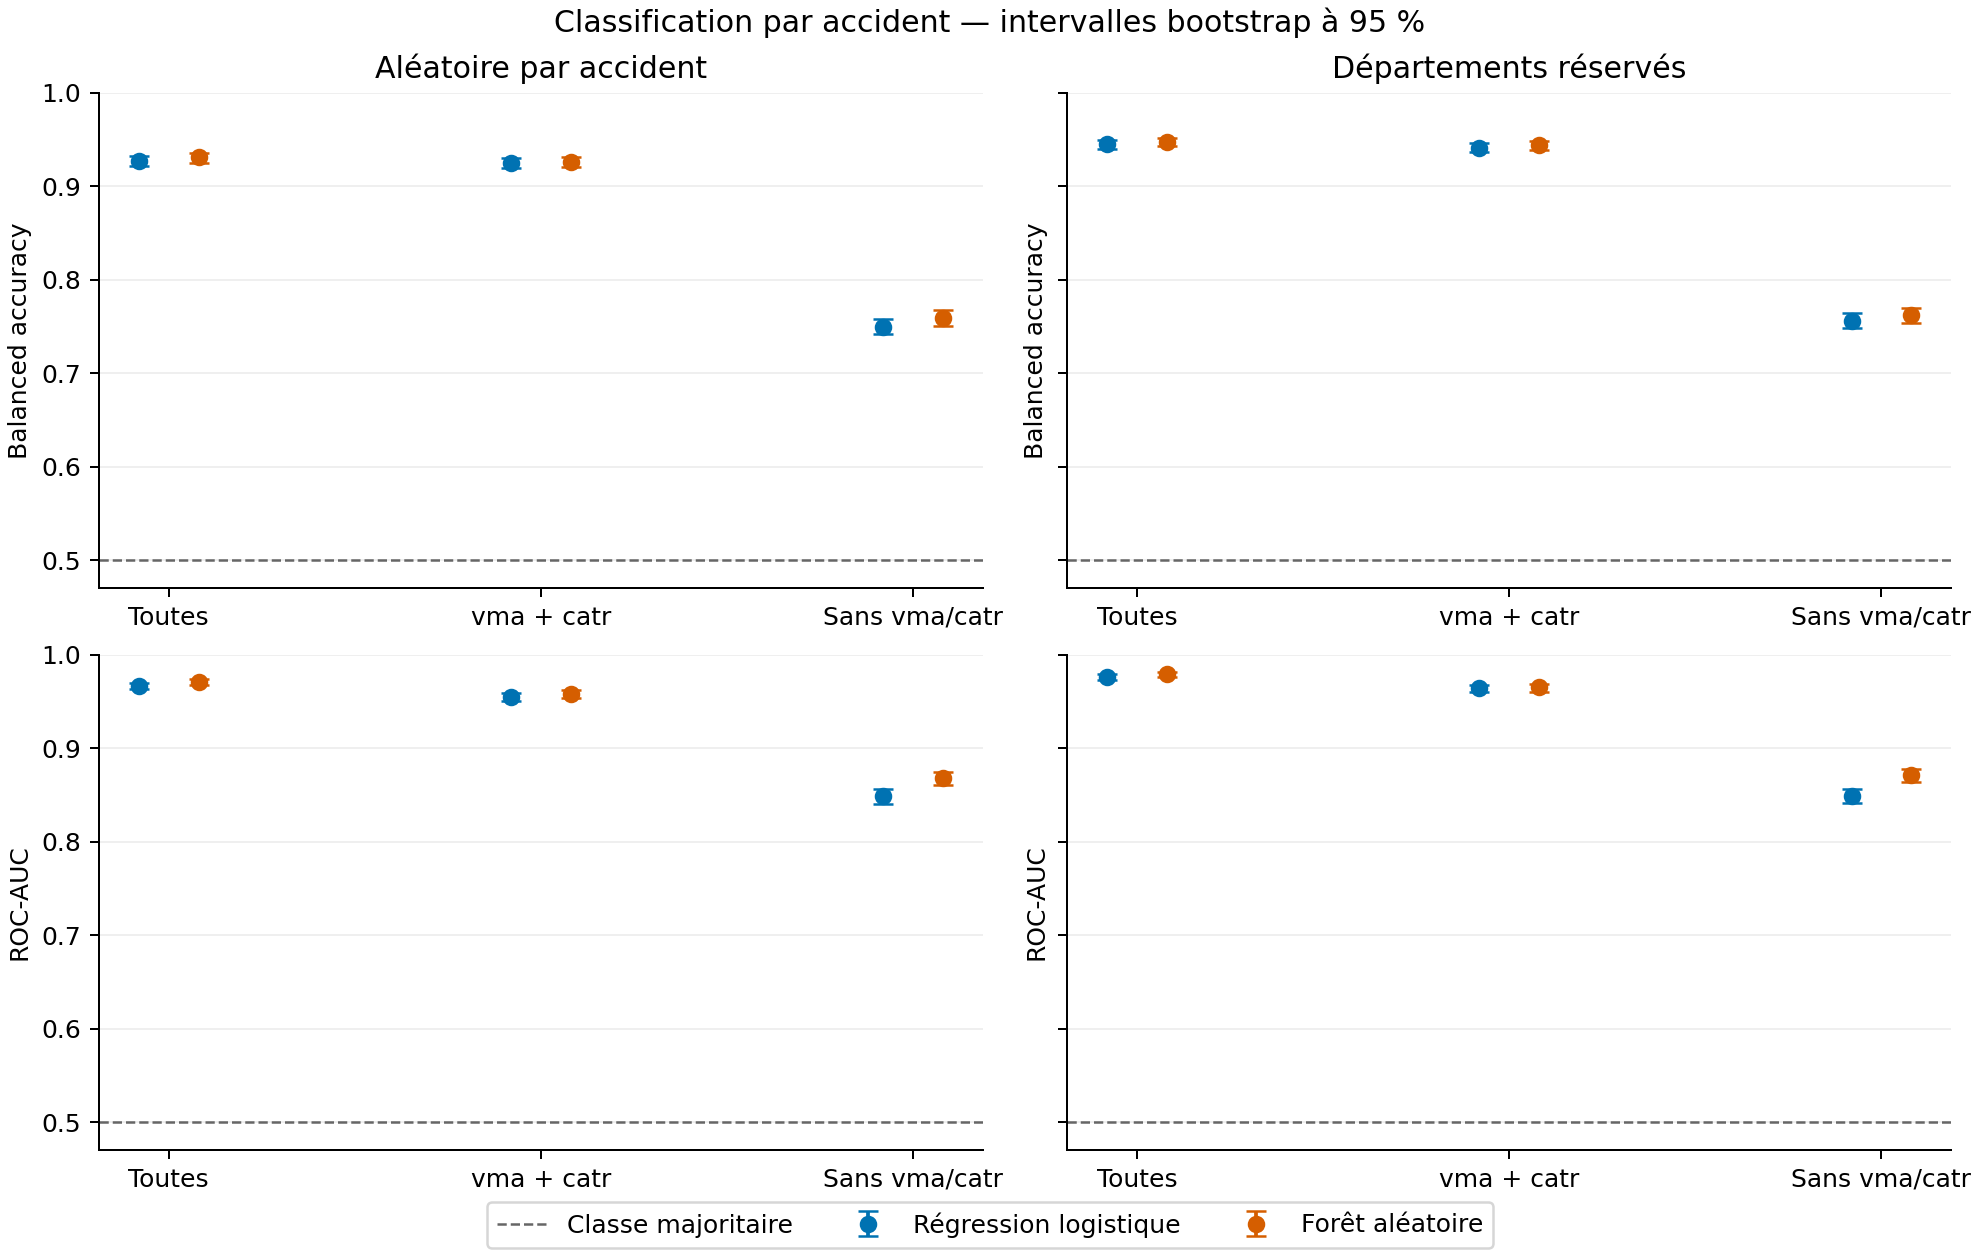

In [5]:
display(metrics[['split', 'features', 'model', 'balanced_accuracy', 'macro_f1', 'roc_auc']])
forest = metrics[metrics.model.eq('forest')]
display(forest[['split', 'features', 'balanced_accuracy', 'balanced_accuracy_low', 'balanced_accuracy_high']])
display(Image(filename=str(ROOT / 'results/figures/performance.png')))


,split,comparison,metric,difference,low,high
0,random_accident,all/forest - all/logistic,balanced_accuracy,0.0042,0.0015,0.0068
1,random_accident,all/forest - all/logistic,macro_f1,0.0035,0.0009,0.0061
2,random_accident,all/forest - all/logistic,roc_auc,0.0048,0.0028,0.0068
18,random_accident,all/forest - without_road/forest,balanced_accuracy,0.1716,0.1620,0.1807
19,random_accident,all/forest - without_road/forest,macro_f1,0.1652,0.1562,0.1746
20,random_accident,all/forest - without_road/forest,roc_auc,0.1036,0.0971,0.1102
21,geographic,all/forest - all/logistic,balanced_accuracy,0.0024,-0.0005,0.0053
22,geographic,all/forest - all/logistic,macro_f1,0.0025,-0.0005,0.0052
23,geographic,all/forest - all/logistic,roc_auc,0.0028,0.0009,0.0047
39,geographic,all/forest - without_road/forest,balanced_accuracy,0.1855,0.1766,0.1943


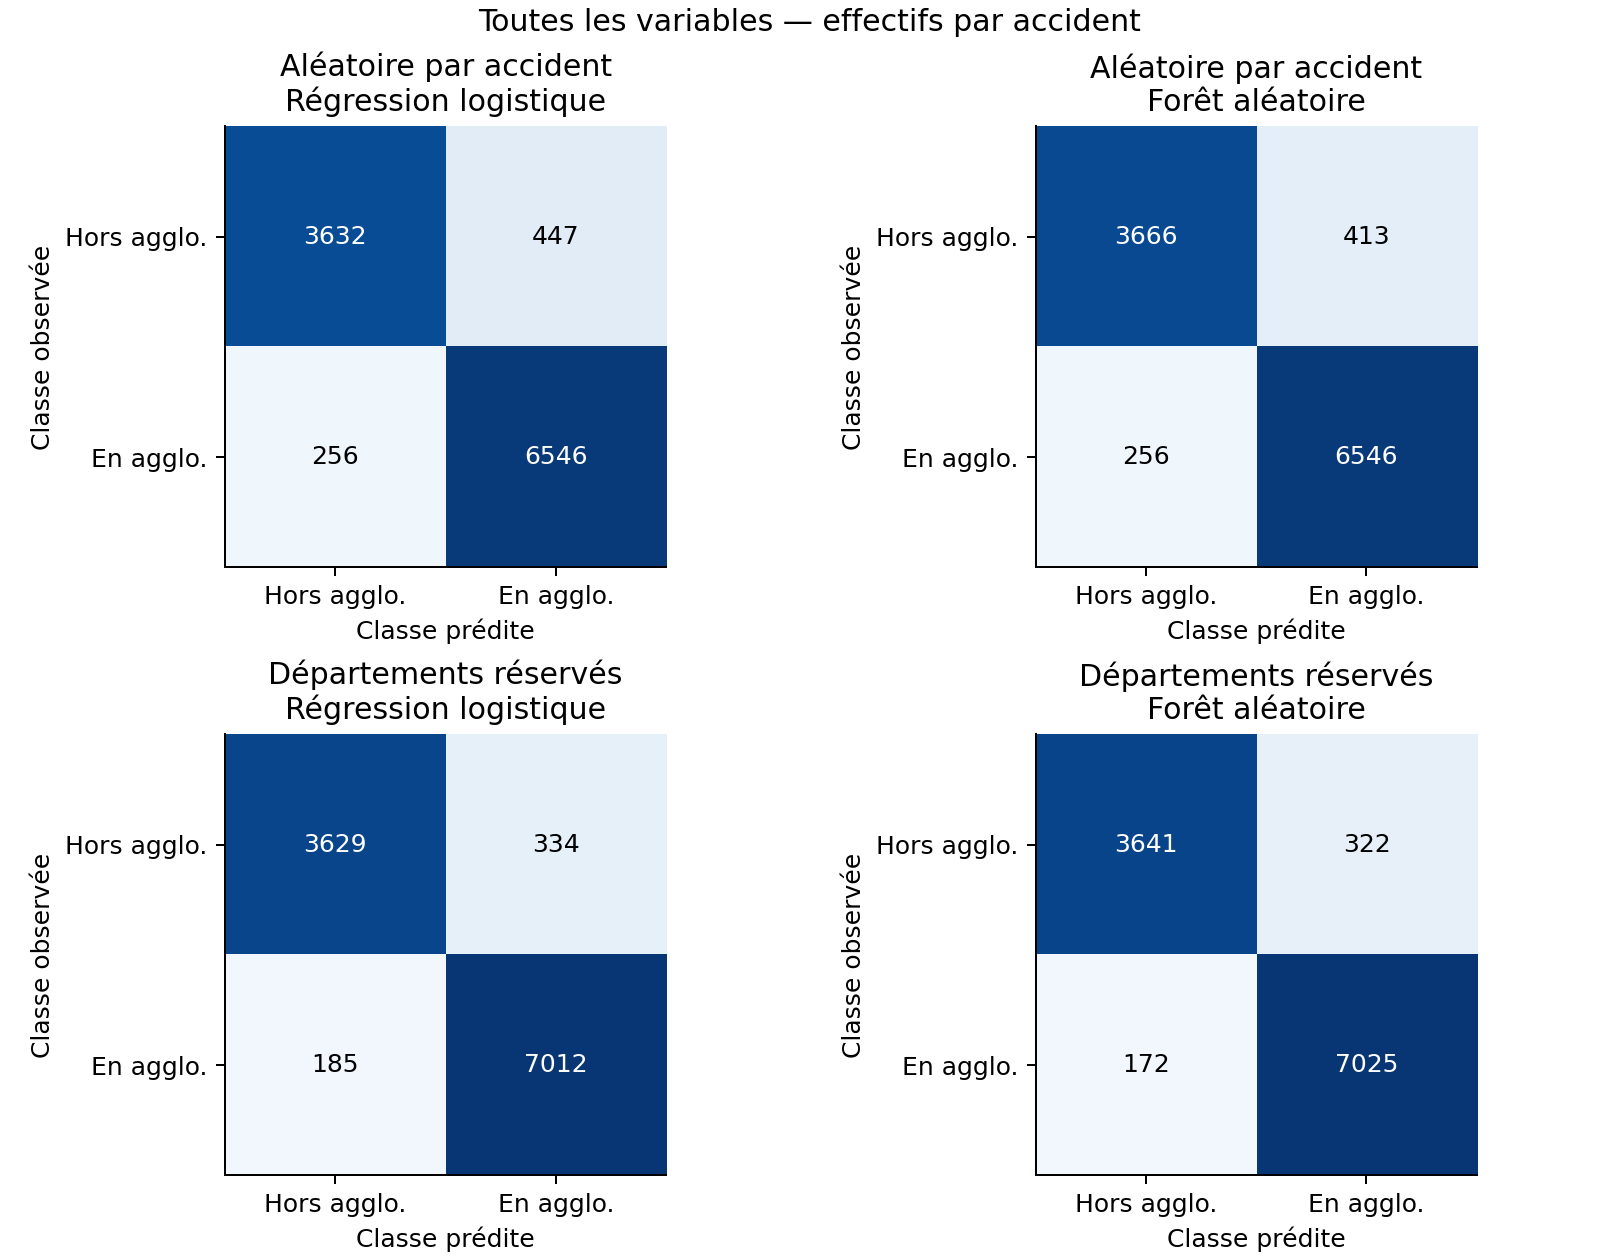

In [6]:
display(differences[
    differences.comparison.isin(['all/forest - all/logistic', 'all/forest - without_road/forest'])
][['split', 'comparison', 'metric', 'difference', 'low', 'high']])
display(Image(filename=str(ROOT / 'results/figures/confusion.png')))


## Résultats et portée

**La dépendance routière persiste dans les deux évaluations.** Pour la forêt, retirer `vma/catr` fait passer la balanced accuracy de 0,9306 à 0,7589 en aléatoire, et de 0,9474 à 0,7619 en géographique. Les pertes appariées valent respectivement 0,1716 [0,1620 ; 0,1807] et 0,1855 [0,1766 ; 0,1943]. Avec ces deux variables seulement, la forêt atteint déjà 0,9258 et 0,9435. Les autres caractéristiques restent informatives, sans compenser leur retrait.

**L’avantage de la forêt dépend de la métrique.** Toutes variables incluses, son gain de balanced accuracy sur la logistique est de 0,0042 [0,0015 ; 0,0068] en aléatoire, mais 0,0024 [−0,0005 ; 0,0053] en géographique : ce dernier intervalle inclut zéro. Son gain géographique de ROC-AUC est positif, 0,0028 [0,0009 ; 0,0047]. Une supériorité générale sur toutes les métriques n’est donc pas établie.

**Le transfert géographique n’entraîne pas de baisse sur cette sélection.** Les tests ne portent toutefois pas sur les mêmes accidents, et les distributions diffèrent. La proportion en agglomération vaut 62,51 % en test aléatoire et 64,49 % en test géographique. Ces résultats ne prouvent pas qu’une séparation territoriale améliore les modèles ou que tous les départements se comporteraient ainsi.

La corrélation de `vma/catr` avec `agg` n’est pas en elle-même une preuve de fuite. Les ablations établissent une dépendance prédictive au contexte routier. Elles ne démontrent ni une cause d’accident ni un effet causal des limitations de vitesse.

## Limites et reproduction

Une seule année, un seul tirage territorial et aucune validation temporelle ; petits effectifs de certains territoires ; erreurs de saisie et processus des lieux multiples imparfaitement documenté ; perte d’information par agrégation ; indépendance spatiale des accidents non garantie. Les règles de plausibilité et la période fixe de 31 jours pour le jour du mois sont des choix de représentation dont la sensibilité n’est pas évaluée ici.

Il n’existe dans ces fichiers ni groupe de trajets sans accident ni dénominateur d’exposition. Aucun résultat ne permet d’estimer le risque d’accident ou d’attribuer une causalité à une variable.

Depuis la racine du dépôt :

```bash
python -m pip install -r requirements.txt
python -m src.download_data
python -m unittest discover -s tests -v
python -m src.experiment
python -m src.report
```

Les cellules de ce notebook lisent les résultats sauvegardés ; l’entraînement est effectué par `src.experiment`. Versions, paramètres et empreintes de l’exécution figurent dans [run_metadata.json](../results/run_metadata.json). Les [18 matrices](../results/confusion_matrices.json) et [intervalles complets](../results/summary.md) sont disponibles séparément. Les données brutes et prédictions individuelles restent locales.